# Cats and Dogs · CNN Contest

**Elisei Ivanov · Group J4132 · Task 4, Part 3**

The task is to classify each photo as a cat or a dog. I trained ResNet34 and ResNet50 from random weights on the supplied training images. The final ensemble is version 4.

## Setup

In [1]:
from pathlib import Path
from zipfile import ZipFile
import hashlib
import io
import json

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageOps
import torch
from torch.utils.data import DataLoader, Dataset
from torchvision import models

DATA_DIR = Path.cwd()

if not (DATA_DIR / "Task_4_Contest_v4_bundle.zip").is_file() or not (DATA_DIR / "Cats_and_Dogs.zip").is_file():
    import lzma
    import shutil
    from google.colab import drive

    drive.mount("/content/drive")
    source_dir = Path("/content/drive/MyDrive/MLT_HW4")
    for name in ("Cats_and_Dogs.zip", "Task_4_Contest_v4_bundle.zip"):
        target = DATA_DIR / name
        if target.is_file():
            continue
        partial = target.with_suffix(".partial")
        if (source_dir / name).is_file():
            shutil.copyfile(source_dir / name, partial)
        else:
            with lzma.open(source_dir / (name + ".xz"), "rb") as src, partial.open("wb") as dst:
                shutil.copyfileobj(src, dst, 1024 * 1024)
        partial.replace(target)
TRAIN_FROM_SCRATCH = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(4)

data_path = DATA_DIR / "Cats_and_Dogs.zip"
bundle_path = DATA_DIR / "Task_4_Contest_v4_bundle.zip"
photos = ZipFile(data_path)
bundle = ZipFile(bundle_path)
print("Device:", device)

Device: cuda


## Data

I kept the original train, validation and test splits. Five duplicate training files were excluded. Validation was used to select checkpoints and the ensemble. Test was used after that choice.

In [2]:
manifest = json.loads(bundle.read("experiment_manifest.json"))
with data_path.open("rb") as source:
    assert hashlib.file_digest(source, "sha256").hexdigest() == manifest["archive_sha256"]

splits = {}
for split in ("train", "val", "test"):
    paths = json.loads(bundle.read(f"{split}_paths.json"))
    splits[split] = paths
    assert len(paths) == manifest["split_counts"][split]
    cats = sum(path.split("/")[1] == "cats" for path in paths)
    print(f"{split:5}  {len(paths):5} images   {cats:5} cats   {len(paths) - cats:5} dogs")

first_path = splits["train"][0]
prefix, = [name[:-len(first_path)] for name in photos.namelist()
           if name.endswith("/Cats_and_Dogs/" + first_path) and "__MACOSX/" not in name]
print("First training files:", ", ".join(Path(p).name for p in splits["train"][:3]))

train  19995 images    9997 cats    9998 dogs
val     2490 images    1240 cats    1250 dogs
test    2500 images    1250 cats    1250 dogs
First training files: cat.0.jpg, cat.1.jpg, cat.10.jpg


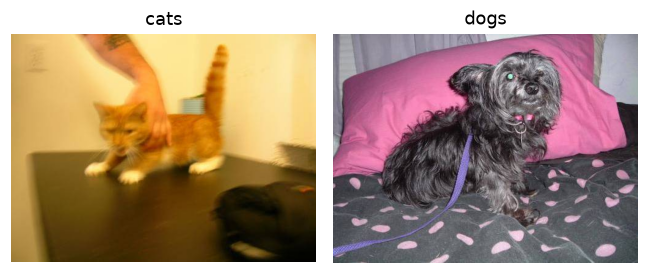

In [3]:
def read_photo(path):
    with photos.open(prefix + path) as file, Image.open(file) as image:
        return ImageOps.exif_transpose(image).convert("RGB")


fig, axes = plt.subplots(1, 2, figsize=(6, 2.8))
for ax, label in zip(axes, ("cats", "dogs")):
    path = next(p for p in splits["train"] if p.split("/")[1] == label)
    ax.imshow(read_photo(path))
    ax.set_title(label)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Training

Both networks started with `weights=None`. Each model kept its own weights when the image size increased. I used AdamW, random crops, horizontal flips and changes in brightness and contrast. MixUp blends two images and their labels. CutMix replaces a patch with a patch from another image.

| Image size | Epochs per model | Learning rate | MixUp probability* | CutMix probability |
|---|---:|---:|---:|---:|
| 224 × 224 | 180 | 0.001 | 0.50 | 0.50 |
| 320 × 320 | 25 | 0.00005 | 0.15 | 0 |
| 384 × 384 | 15 | 0.00003 | 0.10 | 0 |

\*When CutMix is applied, it takes priority over MixUp. At each stage I compared the current weights and their exponential moving average on validation and kept the best checkpoint.

The archive includes the full training loop in `contest_v4.py`. To repeat both training chains, set `TRAIN_FROM_SCRATCH = True` in Setup and run all cells. This option takes several GPU hours and needs about 30 GB of free space for image caches and checkpoints. It saves each new training run in its own folder.

In [4]:
selection = json.loads(bundle.read("contest_v4_selection.json"))
members = selection["selected"]["models"]
weights = selection["selected"]["weights"]
assert weights == [0.25] * 4 and not selection["selected"]["flip"]

def run_folder(member):
    version, name = member.split(":")
    return f"runs_{version}/{name}"


def repeat_training():
    import shutil
    import sys
    import tempfile

    work = Path(tempfile.mkdtemp(prefix="contest_training_", dir=DATA_DIR))
    for name in bundle.namelist():
        if name.endswith(("config.json", "_paths.json", "_labels.npy")) or name in (
            "contest_v4.py", "inference_v4.py"
        ):
            bundle.extract(name, work)
    for paths in splits.values():
        for path in paths:
            target = work / "Cats_and_Dogs" / path
            target.parent.mkdir(parents=True, exist_ok=True)
            with photos.open(prefix + path) as src, target.open("wb") as dst:
                shutil.copyfileobj(src, dst)

    sys.path.insert(0, str(work))
    import inference_v4
    inference_v4.ROOT = inference_v4.train.ROOT = work
    saved = {}
    return work, ["v4:" + inference_v4.retrain(member, saved) for member in members]


if TRAIN_FROM_SCRATCH:
    training_dir, active_members = repeat_training()
else:
    active_members = members

print("Weights:", "new training run" if TRAIN_FROM_SCRATCH else "saved contest checkpoints")

Weights: saved contest checkpoints


## Learning curves

The lines show the validation results from each training stage. The vertical marks show when the image size increased. Each epoch uses the result of the better of the current model and its moving average, as recorded during training.

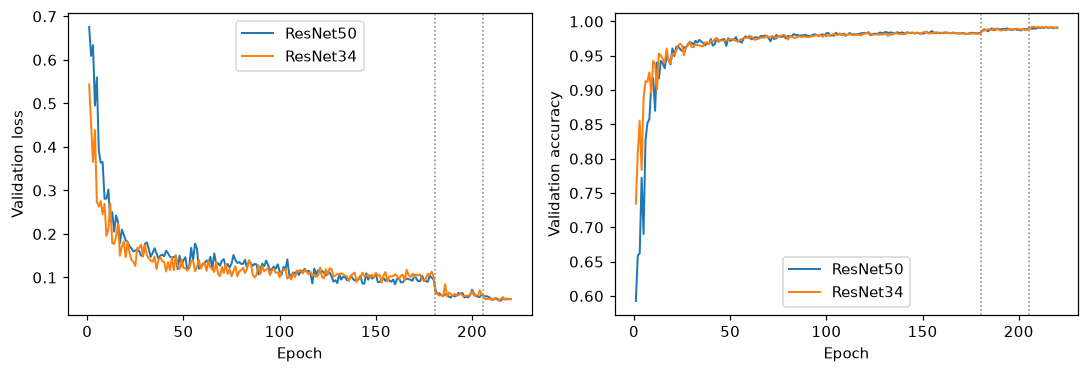

In [5]:
def read_record(member, filename):
    path = f"{run_folder(member)}/{filename}"
    if TRAIN_FROM_SCRATCH:
        return json.loads((training_dir / path).read_text())
    return json.loads(bundle.read(path))


def stage_history(member):
    config = read_record(member, "config.json")
    parent = config.get("init")
    history = []
    if parent:
        if ":" not in parent:
            parent = member.split(":")[0] + ":" + parent
        history = stage_history(parent)
    return history + read_record(member, "history.json")


fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for member in active_members:
    config = read_record(member, "config.json")
    if config.get("bn_recalibrated"):
        continue
    rows = stage_history(member)
    for ax, metric in zip(axes, ("val_loss", "val_accuracy")):
        ax.plot(range(1, len(rows) + 1), [row[metric] for row in rows],
                label=config["model"].replace("resnet", "ResNet"), linewidth=1.3)
for ax, label in zip(axes, ("Validation loss", "Validation accuracy")):
    for epoch in (180.5, 205.5):
        ax.axvline(epoch, color="gray", linestyle=":", linewidth=1)
    ax.set(xlabel="Epoch", ylabel=label)
    ax.legend()
fig.tight_layout()
plt.show()

## Ensemble

Each network has two checkpoints: the selected weights and a copy with BatchNorm statistics recalculated on training images. For every photo I average the **four class probabilities** with weight 0.25 each and choose the class with the larger mean. Each photo is evaluated once per checkpoint at 384 × 384.

In [6]:
def load_model(member):
    path = f"{run_folder(member)}/best.pt"
    if TRAIN_FROM_SCRATCH:
        checkpoint = torch.load(training_dir / path, map_location="cpu", weights_only=True)
    else:
        data = bundle.read(path)
        assert hashlib.sha256(data).hexdigest() == selection["weight_sha256"][member]
        checkpoint = torch.load(io.BytesIO(data), map_location="cpu", weights_only=True)

    config = checkpoint["config"]
    assert config["pretrained"] is False and config["size"] == 384
    assert config["class_to_idx"] == {"cats": 0, "dogs": 1}
    architecture = {"resnet34": models.resnet34, "resnet50": models.resnet50}
    model = architecture[config["model"]](weights=None, num_classes=2)
    model.load_state_dict(checkpoint["state_dict"])
    return model.to(device).eval()


ensemble = [load_model(member) for member in active_members]
print("Loaded", len(ensemble), "checkpoints")

Loaded 4 checkpoints


I keep the aspect ratio and pad each photo to a square. The same resize, padding and channel normalization are used for validation, test and a single photo.

In [7]:
def image_tensor(image):
    image = ImageOps.pad(image, (384, 384), method=Image.Resampling.BILINEAR,
                         color=(124, 116, 104))
    return torch.from_numpy(np.array(image))


mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

@torch.inference_mode()
def class_probabilities(batch):
    images = batch.to(device).permute(0, 3, 1, 2).float() / 255
    images = (images - mean) / std
    with torch.autocast(device.type, enabled=device.type == "cuda"):
        probabilities = [model(images).float().softmax(dim=1) for model in ensemble]
    return sum(weight * p for weight, p in zip(weights, probabilities))

## Accuracy

Both scores below are calculated from the active models and the image labels.

In [8]:
class PhotoDataset(Dataset):
    def __init__(self, paths):
        self.paths = paths

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        path = self.paths[index]
        label = {"cats": 0, "dogs": 1}[path.split("/")[1]]
        return image_tensor(read_photo(path)), label


def evaluate(split):
    dataset = PhotoDataset(splits[split])
    correct = 0
    for images, labels in DataLoader(dataset, batch_size=16, shuffle=False):
        predictions = class_probabilities(images).argmax(dim=1).cpu()
        correct += (predictions == labels).sum().item()
    return correct, len(dataset)


for split, title in (("val", "Validation"), ("test", "Test")):
    correct, total = evaluate(split)
    print(f"{title:10} {correct:4}/{total}   accuracy {correct / total:.2%}   errors {total - correct}")

Validation 2478/2490   accuracy 99.52%   errors 12
Test       2477/2500   accuracy 99.08%   errors 23


## Single image

Pass a local photo path to `predict_image` to get the class and its probability. The example photo is included in the weights archive.

Prediction: dog (97.8%)


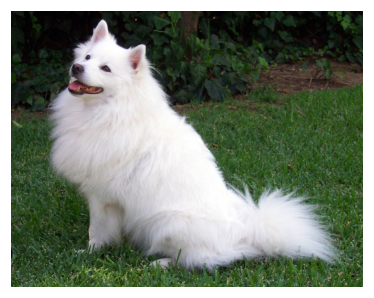

In [9]:
def predict_image(path_or_file):
    with Image.open(path_or_file) as photo:
        rgb = ImageOps.exif_transpose(photo).convert("RGB")
    probabilities = class_probabilities(image_tensor(rgb).unsqueeze(0))[0]
    index = probabilities.argmax().item()
    return ("cat", "dog")[index], probabilities[index].item()


example = bundle.read("custom_dog.jpg")
label, probability = predict_image(io.BytesIO(example))
print(f"Prediction: {label} ({probability:.1%})")
with Image.open(io.BytesIO(example)) as photo:
    plt.figure(figsize=(3.5, 3.5))
    plt.imshow(photo)
    plt.axis("off")
    plt.tight_layout()
    plt.show()